# Exploratory Analysis: K12 Student Data

This notebook explores the cleaned analysis tables built by `scripts/02_clean_and_validate.py`. It answers the project business questions with simple descriptive analysis: averages, percentages, distributions, and group comparisons.

Every table uses the same analysis population: the 110 students listed as Active in the student table. Seven Withdrawn students are excluded, and the reasons are documented in `docs/methodology_and_limitations.md`.

The charts are saved to `assets/charts` so the README and the dashboard preview can use the same images.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# The project uses one restrained palette across every chart.
NAVY = "#16324F"
GOLD = "#D9A441"
GRAY = "#6B7280"

students = pd.read_csv("data/processed/dim_student.csv")
attendance = pd.read_csv("data/processed/fact_attendance.csv")
assessments = pd.read_csv("data/processed/fact_assessment.csv")
discipline = pd.read_csv("data/processed/fact_discipline.csv")
summary = pd.read_csv("data/processed/fact_student_summary.csv")

print("dim_student rows:", len(students))
print("fact_attendance rows:", len(attendance))
print("fact_assessment rows:", len(assessments))
print("fact_discipline rows:", len(discipline))
print("fact_student_summary rows:", len(summary))

dim_student rows: 110
fact_attendance rows: 108
fact_assessment rows: 107
fact_discipline rows: 109
fact_student_summary rows: 110


## Headline KPIs

The first step is the headline picture for the whole population. Counts of students differ slightly between measures because two students have no attendance row and three have no assessment row. Each average below states its own base in words.

In [2]:
total_students = students["Student_ID"].nunique()
average_attendance = attendance["Attendance_Rate"].mean()
average_score = assessments["Score"].mean()
percent_met = 100 * (assessments["Benchmark"] == "Met").mean()
below_count = int((assessments["Benchmark"] == "Below").sum())
chronic_count = int((attendance["Is_Chronic_Absence"] == "Yes").sum())
chronic_rate = 100 * (attendance["Is_Chronic_Absence"] == "Yes").mean()
total_incidents = int(discipline["Incidents"].sum())

print(f"Total students in the analysis population: {total_students}")
print(f"Average attendance rate across {len(attendance)} students with attendance: {average_attendance:.2f}")
print(f"Average score across {len(assessments)} students with an assessment: {average_score:.2f}")
print(f"Share of assessed students recorded as Met: {percent_met:.1f} percent")
print(f"Students recorded as Below: {below_count}")
print(f"Students in the chronic absence group: {chronic_count} of {len(attendance)}, which is {chronic_rate:.1f} percent")
print(f"Total discipline incidents across {len(discipline)} students: {total_incidents}")

Total students in the analysis population: 110
Average attendance rate across 108 students with attendance: 91.84
Average score across 107 students with an assessment: 78.48
Share of assessed students recorded as Met: 75.7 percent
Students recorded as Below: 26
Students in the chronic absence group: 36 of 108, which is 33.3 percent
Total discipline incidents across 109 students: 144


What this shows: attendance averages 91.84 percent and scores average 78.48, with three quarters of assessed students at or above the benchmark score of 70. The figure that stands out is the chronic absence group. One third of students with attendance records sit below 90 percent attendance under the project definition.

What this does not show: these are whole population averages. They hide the spread between students, which the next two sections look at.

## How attendance is spread across students

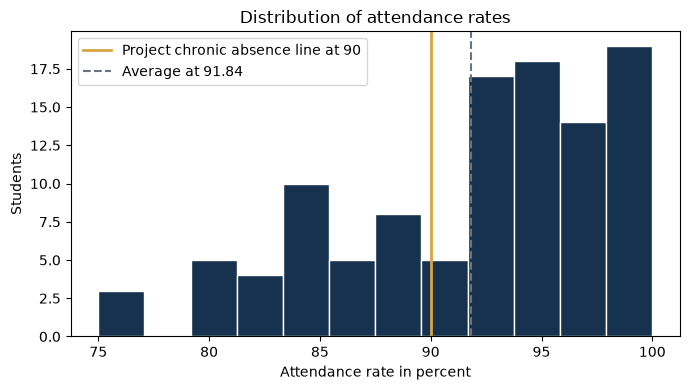

count    108.00
mean      91.84
std        6.30
min       75.00
25%       87.70
50%       93.55
75%       96.42
max      100.00
Name: Attendance_Rate, dtype: float64


In [3]:
plt.figure(figsize=(7, 4))
plt.hist(attendance["Attendance_Rate"], bins=12, color=NAVY, edgecolor="white")
plt.axvline(90, color=GOLD, linewidth=2, label="Project chronic absence line at 90")
plt.axvline(average_attendance, color=GRAY, linestyle="--", label="Average at 91.84")
plt.xlabel("Attendance rate in percent")
plt.ylabel("Students")
plt.title("Distribution of attendance rates")
plt.legend()
plt.tight_layout()
plt.savefig("assets/charts/attendance_distribution.png", dpi=150)
plt.show()

print(attendance["Attendance_Rate"].describe().round(2))

Most students cluster between 90 and 100 percent, and half of all students sit at or above 93.55 percent. The average of 91.84 is pulled down by a smaller group with much lower attendance. The lowest rate in the data is 75 percent, and 21 students sit below 85 percent.

This is why the project reports attendance in bands as well as an average. The average looks comfortable while a group of about one in five students attends at a level that most schools would want to look at more closely.

## How scores are spread across students

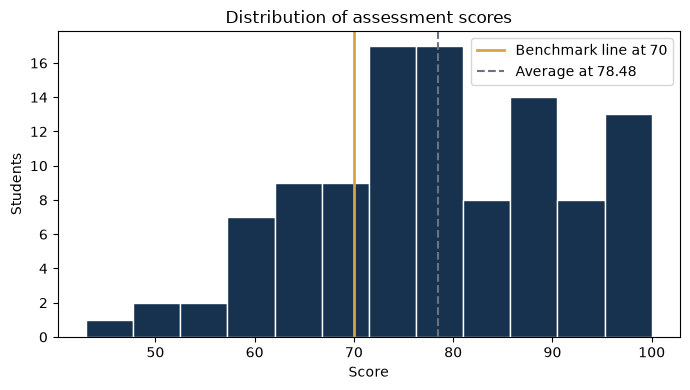

count    107.00
mean      78.48
std       12.93
min       43.00
25%       70.00
50%       78.00
75%       88.00
max      100.00
Name: Score, dtype: float64


In [4]:
plt.figure(figsize=(7, 4))
plt.hist(assessments["Score"], bins=12, color=NAVY, edgecolor="white")
plt.axvline(70, color=GOLD, linewidth=2, label="Benchmark line at 70")
plt.axvline(average_score, color=GRAY, linestyle="--", label="Average at 78.48")
plt.xlabel("Score")
plt.ylabel("Students")
plt.title("Distribution of assessment scores")
plt.legend()
plt.tight_layout()
plt.savefig("assets/charts/score_distribution.png", dpi=150)
plt.show()

print(assessments["Score"].describe().round(2))

Scores run from 43 to 100 with a median of 78. A quarter of assessed students score at or below 70, which is the benchmark line itself. That means the Below group of 26 students is not a small tail of very low scores. It includes students scoring in the sixties who sit close to the line.

## Attendance by grade and by program

Average attendance rate by grade
Grade
5    91.36
6    91.85
7    93.25
8    91.38
Name: Attendance_Rate, dtype: float64

Average attendance rate by program
Program
Core           93.14
MTSS Tier 1    90.08
MTSS Tier 2    90.72
MTSS Tier 3    91.16
Name: Attendance_Rate, dtype: float64

Share of students in the chronic absence group by program, in percent
Program
Core           20.0
MTSS Tier 1    46.4
MTSS Tier 2    44.4
MTSS Tier 3    44.4
Name: Is_Chronic_Absence, dtype: float64


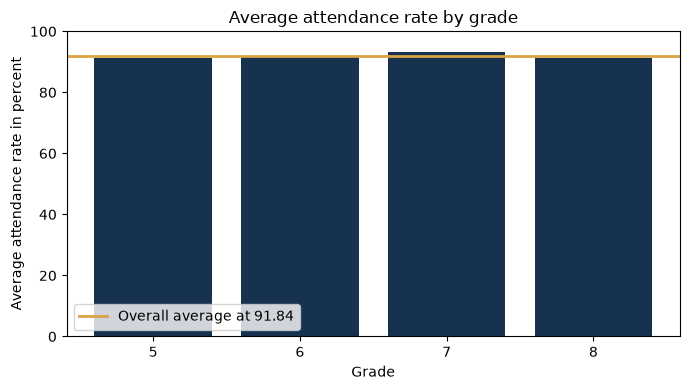

In [5]:
attendance_by_grade = attendance.groupby("Grade")["Attendance_Rate"].mean().round(2)
attendance_by_program = summary.groupby("Program")["Attendance_Rate"].mean().round(2)
chronic_by_program = summary.groupby("Program")["Is_Chronic_Absence"].apply(
    lambda values: round(100 * (values == "Yes").mean(), 1)
)
print("Average attendance rate by grade")
print(attendance_by_grade)
print()
print("Average attendance rate by program")
print(attendance_by_program)
print()
print("Share of students in the chronic absence group by program, in percent")
print(chronic_by_program)

plt.figure(figsize=(7, 4))
plt.bar(attendance_by_grade.index.astype(str), attendance_by_grade.values, color=NAVY)
plt.axhline(average_attendance, color=GOLD, linewidth=2, label="Overall average at 91.84")
plt.xlabel("Grade")
plt.ylabel("Average attendance rate in percent")
plt.title("Average attendance rate by grade")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.savefig("assets/charts/attendance_by_grade.png", dpi=150)
plt.show()


Grade 7 records the highest average attendance at 93.25 percent, and the other three grades sit close together between 91.36 and 91.85. Grade level alone does not separate attendance much in this data.

Program shows a wider spread. Core students average 93.14 percent, while MTSS Tier 1 students average 90.08 percent, and half of the Tier 1 students with attendance records fall in the chronic absence group. Tier 1 is the lightest support tier in the MTSS model, so this pattern is worth a closer look by the school. It is a pattern in one snapshot, not evidence about whether the tier placement is wrong.

## Assessment performance by grade and by subject

Share of students recorded as Met by grade, in percent
Grade
5    76.0
6    63.6
7    81.8
8    78.9
Name: Benchmark, dtype: float64

Average score by subject
Assessment
ELA        81.69
Math       76.68
Science    77.46
Name: Score, dtype: float64

Share of students recorded as Met by subject, in percent
Assessment
ELA        87.5
Math       76.5
Science    65.9
Name: Benchmark, dtype: float64


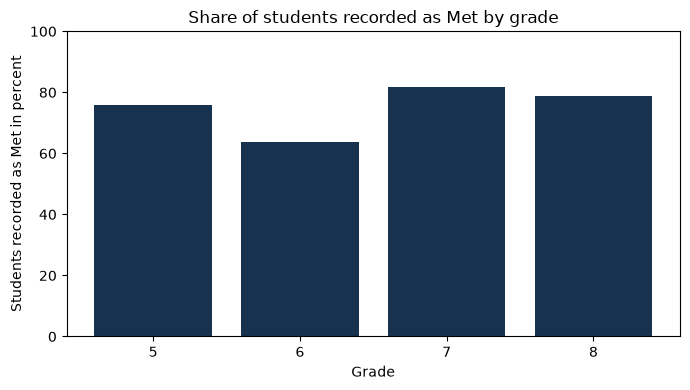

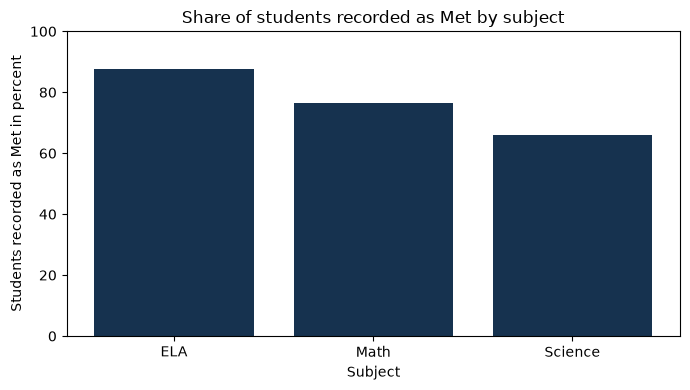

In [6]:
percent_met_by_grade = assessments.groupby("Grade")["Benchmark"].apply(
    lambda values: round(100 * (values == "Met").mean(), 1)
)
score_by_subject = assessments.groupby("Assessment")["Score"].mean().round(2)
percent_met_by_subject = assessments.groupby("Assessment")["Benchmark"].apply(
    lambda values: round(100 * (values == "Met").mean(), 1)
)
print("Share of students recorded as Met by grade, in percent")
print(percent_met_by_grade)
print()
print("Average score by subject")
print(score_by_subject)
print()
print("Share of students recorded as Met by subject, in percent")
print(percent_met_by_subject)

plt.figure(figsize=(7, 4))
plt.bar(percent_met_by_grade.index.astype(str), percent_met_by_grade.values, color=NAVY)
plt.xlabel("Grade")
plt.ylabel("Students recorded as Met in percent")
plt.title("Share of students recorded as Met by grade")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("assets/charts/percent_met_by_grade.png", dpi=150)
plt.show()

plt.figure(figsize=(7, 4))
plt.bar(percent_met_by_subject.index, percent_met_by_subject.values, color=NAVY)
plt.xlabel("Subject")
plt.ylabel("Students recorded as Met in percent")
plt.title("Share of students recorded as Met by subject")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("assets/charts/percent_met_by_subject.png", dpi=150)
plt.show()

Grade 6 has the weakest benchmark results, with 63.6 percent of its assessed students recorded as Met against 81.8 percent in grade 7. Its average score of 76.50 is also the lowest of the four grades.

By subject, ELA records the highest share at Met with 87.5 percent, then Math at 76.5 percent, then Science at 65.9 percent. Read this with the project caveat in mind: each student took exactly one assessment in one subject, so the subject rows compare different groups of students. The gap may say as much about which students sat each subject as about the subjects themselves.

## Attendance band and assessment score

This section tests the assumption many readers bring to school data: that students who attend more score higher.

Average score by attendance band
Attendance_Band
At Risk             77.20
Needs Monitoring    81.27
On Track            81.07
Strong              76.60
Name: Score, dtype: float64

Students with both attendance and a score: 105
Correlation between attendance rate and score: -0.06


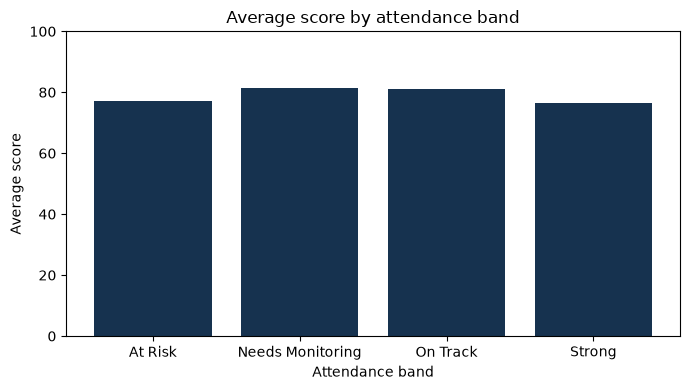

In [7]:
band_order = ["At Risk", "Needs Monitoring", "On Track", "Strong"]
band_scores = summary.groupby("Attendance_Band")["Score"].mean().round(2).reindex(band_order)
print("Average score by attendance band")
print(band_scores)

students_with_both = summary.dropna(subset=["Attendance_Rate", "Score"])
correlation = students_with_both["Attendance_Rate"].corr(students_with_both["Score"])
print()
print(f"Students with both attendance and a score: {len(students_with_both)}")
print(f"Correlation between attendance rate and score: {correlation:.2f}")

plt.figure(figsize=(7, 4))
plt.bar(band_scores.index, band_scores.values, color=NAVY)
plt.xlabel("Attendance band")
plt.ylabel("Average score")
plt.title("Average score by attendance band")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("assets/charts/score_by_band.png", dpi=150)
plt.show()


The expected pattern does not appear in this data. The correlation between attendance rate and score is −0.06 across 105 students, which is as close to no linear relationship as a real dataset usually gets. The band averages agree with that reading. Students in the Strong attendance band average 76.60, while students in the Needs Monitoring band average 81.27 and students in the On Track band average 81.07.

What this shows: in this single snapshot, knowing a student attendance band tells you very little about their score.

What this does not show: it does not prove attendance has no effect on learning. The data holds one assessment per student, the subject mix differs across bands, group sizes are small, and nothing here records prior achievement, teaching, or circumstances at home. The honest conclusion is narrow. This dataset cannot support a claim in either direction about attendance causing scores, and any report that used these numbers to claim one would be overstating the evidence.

## Discipline incidents

Average incidents per student by grade
Grade
5    1.28
6    1.23
7    0.95
8    1.60
Name: Incidents, dtype: float64

Students with at least one incident: 78 of 109, which is 71.6 percent
Students with three or more incidents: 14


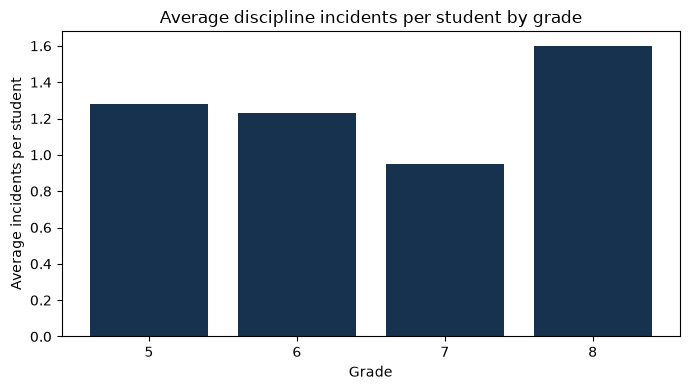

In [8]:
incidents_by_grade = discipline.groupby("Grade")["Incidents"].mean().round(2)
students_with_incidents = int((discipline["Incidents"] > 0).sum())
share_with_incidents = 100 * (discipline["Incidents"] > 0).mean()
students_with_three_plus = int((discipline["Incidents"] >= 3).sum())
print("Average incidents per student by grade")
print(incidents_by_grade)
print()
print(f"Students with at least one incident: {students_with_incidents} of {len(discipline)}, which is {share_with_incidents:.1f} percent")
print(f"Students with three or more incidents: {students_with_three_plus}")

plt.figure(figsize=(7, 4))
plt.bar(incidents_by_grade.index.astype(str), incidents_by_grade.values, color=NAVY)
plt.xlabel("Grade")
plt.ylabel("Average incidents per student")
plt.title("Average discipline incidents per student by grade")
plt.tight_layout()
plt.savefig("assets/charts/incidents_by_grade.png", dpi=150)
plt.show()

Incidents are spread widely but shallowly. About seven in ten students have at least one recorded incident, yet the average is only 1.32 incidents per student and just 14 students account for three or more incidents each.

Grade 8 records the highest rate at 1.60 incidents per student and the highest total at 64 incidents. Grade 8 is also the largest grade with 40 students, which is why this notebook compares incidents per student rather than totals. Grade 7 records the lowest rate at 0.95 per student.

## Assessment results by month

Average score by assessment month
Assessment_Month
2026-01    80.29
2026-02    78.47
2026-03    77.35
2026-04    79.53
Name: Score, dtype: float64

Assessments recorded by month
Assessment_Month
2026-01    17
2026-02    30
2026-03    43
2026-04    17
dtype: int64


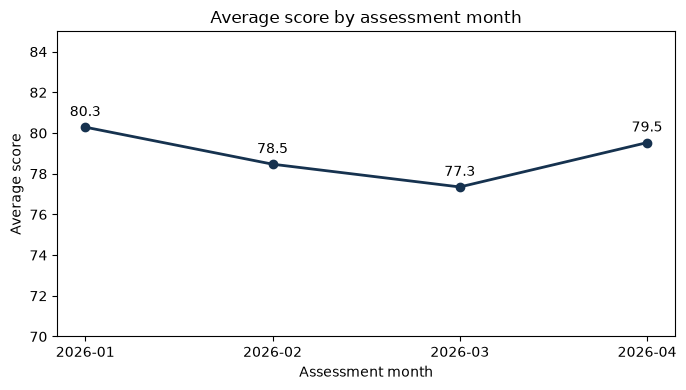

In [9]:
assessments["Assessment_Month"] = pd.to_datetime(assessments["Assessment_Date"]).dt.strftime("%Y-%m")
monthly = assessments.groupby("Assessment_Month")["Score"].mean().round(2)
monthly_counts = assessments.groupby("Assessment_Month").size()
print("Average score by assessment month")
print(monthly)
print()
print("Assessments recorded by month")
print(monthly_counts)

plt.figure(figsize=(7, 4))
plt.plot(monthly.index, monthly.values, color=NAVY, marker="o", linewidth=2)
for month, value in monthly.items():
    plt.annotate(f"{value:.1f}", (month, value), textcoords="offset points", xytext=(0, 8), ha="center")
plt.xlabel("Assessment month")
plt.ylabel("Average score")
plt.title("Average score by assessment month")
plt.ylim(70, 85)
plt.tight_layout()
plt.savefig("assets/charts/score_by_month.png", dpi=150)
plt.show()

Average scores move within a narrow range across the testing window: 80.29 in January, 78.47 in February, 77.35 in March, and 79.53 in April. The counts differ a lot by month, from 17 assessments in January and April to 43 in March.

Because each student appears once and the subject mix changes by month, this is a picture of the testing window rather than a growth trend for the same students. The project reports it as a description of when results landed, not as evidence that performance rose or fell.

## What this analysis cannot show

1. It cannot show cause. Nothing in this data records teaching, prior achievement, or home circumstances, so no result here explains why a pattern exists.
2. It cannot compare subjects fairly for the same students, because each student took one assessment in one subject.
3. It cannot track growth, because each student has a single assessment record rather than a series over time.
4. It describes one school, grades 5 to 8, in one school year, using simulated practice data. The numbers should not be read as findings about any real school.

The value of the analysis is narrower and more useful: one consistent population, checked arithmetic, documented decisions, and a small set of patterns that a school team could investigate with better data.